In [47]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from scipy.stats import norm

rng = np.random.default_rng(100)

def purchase_probability(price):
    price = np.asarray(price, dtype=float)
    return (
        0.55 * np.exp(-np.logaddexp(0.0, (price - 13.9) / 0.8))
        + 0.30 * np.exp(-np.logaddexp(0.0, (price - 30.9) / 1.2))
        + 0.15 * np.exp(-np.logaddexp(0.0, (price - 58.4) / 1.8))
    )

def sales(price=14.0, rng=None, mean_customers=30):
    price = float(price)
    if not np.isfinite(price):
        raise ValueError("price must be finite")
    if price < 0:
        raise ValueError("price must be nonnegative")
    mean_customers = float(mean_customers)
    if not np.isfinite(mean_customers) or mean_customers < 0:
        raise ValueError("mean_customers must be finite and nonnegative")
    rng = np.random.default_rng(rng)
    customer_count = rng.poisson(mean_customers)
    probability = purchase_probability(price)
    return rng.binomial(1, probability, size=customer_count).astype(np.int8)

In [48]:
class PricingExperimentTracker:
    def __init__(self, seed=100):
        self.rng = np.random.default_rng(seed)
        #1D array of individual customer purchase decisions
        self.cache = {}
        self.total_customers_tested = 0
        self.total_revenue_accumulated = 0.0

    def gather_data(self, price, target_customers=100): #get data from a price point up to target_customers
        price = round(float(price), 2)
        if price not in self.cache:
            self.cache[price] = np.array([], dtype=np.int8)

        current_count = len(self.cache[price])
        if current_count < target_customers:
            needed = target_customers - current_count
            new_sales = sales(price=price, rng=self.rng, mean_customers=needed)
            #add new data and track new metrics
            self.cache[price] = np.concatenate([self.cache[price], new_sales])
            self.total_customers_tested += len(new_sales)
            self.total_revenue_accumulated += new_sales.sum() * price

        all_sales = self.cache[price]
        revs = all_sales * price
        n_total = len(all_sales)
        mean_rev = revs.mean() if n_total else 0.0
        std_err = (revs.std(ddof=1) / np.sqrt(n_total)) if n_total > 1 else 0.0

        return {
            "price": price,
            "n_customers": n_total,
            "mean_revenue": mean_rev,
            "std_error": std_err,
            "total_revenue": revs.sum(),
        }

In [49]:
#compare nearby price points (price - step and price + step)
#estimate for local revenue data and run Z-test conf intervals
def estimate_gradient(tracker, price, step=0.5, mean_customers=300, conf_level=0.90):
    price = float(np.clip(price, 0.0, 70.0))
    p_low = max(0.0, round(price - step, 2))
    p_high = min(70.0, round(price + step, 2))
    res_low = tracker.gather_data(p_low, target_customers=mean_customers)
    res_high = tracker.gather_data(p_high, target_customers=mean_customers)
    diff = res_high["mean_revenue"] - res_low["mean_revenue"]
    se = np.sqrt(res_low["std_error"] ** 2 + res_high["std_error"] ** 2)
    gap = p_high - p_low

    c = norm.ppf((1 + conf_level) / 2)
    grad = diff / gap if gap > 0 else 0.0
    grad_se = se / gap if gap > 0 else 0.0

    return { 
    "price": price, 
    "gradient": grad, 
    "gradient_se": grad_se, 
    "ci_low": grad - c * grad_se, 
    "ci_high": grad + c * grad_se, 
    "diff_mean_revenue": diff, 
    "se_diff": se, 
    "p_low": p_low, 
    "p_high": p_high, 
}

In [50]:
def find_optimal_price_algorithm(seed=2026):
    tracker = PricingExperimentTracker(seed=seed)

    #coarse grid search first to eliminate maximums
    coarse_prices = np.arange(0.0, 72.5, 2.5)
    grid_results = [tracker.gather_data(p, target_customers=150) for p in coarse_prices]
    grid_df = pd.DataFrame(grid_results)

    #top 3 candidate regions
    top_candidates = (
        grid_df.sort_values("mean_revenue", ascending=False)
        .head(3)["price"]
        .tolist()
    )

    #redo top candidate regions with added samples
    candidate_evals = [tracker.gather_data(p, target_customers=500) for p in top_candidates]
    best_coarse_price = max(candidate_evals, key=lambda x: x["mean_revenue"])["price"]

    price = best_coarse_price
    learning_rate = 2.0
    step = 0.5
    iterations = 15
    path_history = []

    #does gradient ascent based on the best candidate
    for it in range(iterations):
        grad_info = estimate_gradient(
            tracker,
            price,
            step=step,
            mean_customers=300 + it * 20,
            conf_level=0.90,
        )

        #learning rate decay formula is l_t = l_0 / sqrt(t + 1)
        rate = learning_rate / np.sqrt(it + 1)
        move = np.clip(rate * grad_info["gradient"], -1.5, 1.5)
        next_price = round(float(np.clip(price + move, 0.0, 70.0)), 2)

        path_history.append({
            "iteration": it + 1,
            "current_price": price,
            "gradient": grad_info["gradient"],
            "gradient_se": grad_info["gradient_se"],
            "ci_low": grad_info["ci_low"],
            "ci_high": grad_info["ci_high"],
            "next_price": next_price,
        })
        price = next_price

    #fine grid search
    fine_grid = np.arange(max(0.0, price - 1.0), min(70.0, price + 1.0) + 0.05, 0.10)
    fine_evals = [tracker.gather_data(p, target_customers=800) for p in fine_grid]

    optimal_record = max(fine_evals, key=lambda x: x["mean_revenue"])
    optimal_price = optimal_record["price"]

    return tracker, optimal_price, pd.DataFrame(path_history), grid_df

tracker, opt_price, path_df, grid_df = find_optimal_price_algorithm(seed=2026)

In [51]:
sns.set_theme(style="whitegrid") 
plt.rcParams.update({"font.size": 11, "figure.autolayout": True})

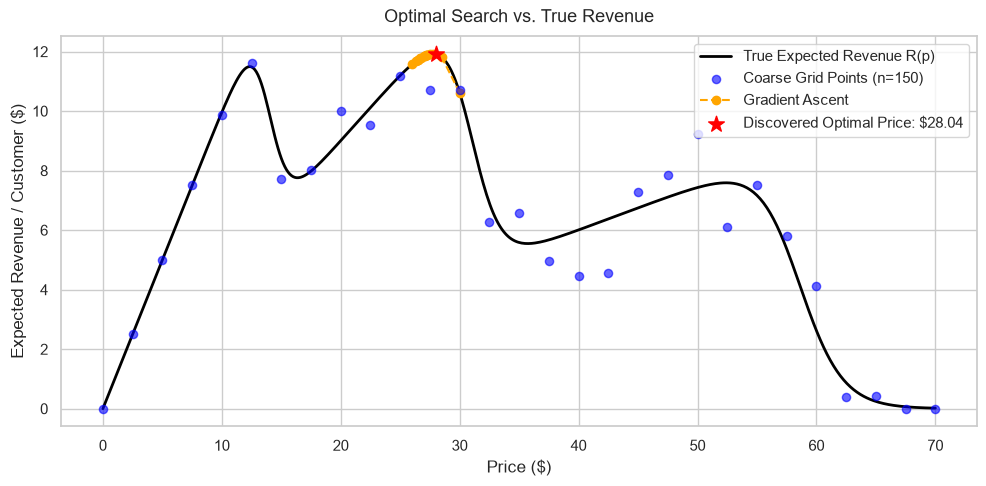

In [52]:
#expected revenue per customer R(p) = p * P(p)
fig, ax = plt.subplots(figsize=(10, 5))
p_dense = np.linspace(0, 70, 500)
rev_dense = p_dense * purchase_probability(p_dense)
ax.plot(
    p_dense,
    rev_dense,
    color="black",
    linewidth=2,
    label="True Expected Revenue R(p)",
)
#coarse grid scatter plot
ax.scatter( 
    grid_df["price"], 
    grid_df["mean_revenue"], 
    color="blue", 
    alpha=0.6, 
    s=35, 
    zorder=3, 
    label="Coarse Grid Points (n=150)", 
)
#gradient ascent test
path_prices = path_df["current_price"].to_numpy()
path_revs = [
    p * purchase_probability(p) for p in path_prices
]
ax.plot(
    path_prices,
    path_revs,
    color="orange",
    linestyle="--",
    marker="o",
    linewidth=1.5,
    label="Gradient Ascent",
)
#optimal revenue and price test
opt_rev = opt_price * purchase_probability(opt_price)
ax.scatter(
    opt_price,
    opt_rev,
    color="red",
    s=140,
    zorder=5,
    marker="*",
    label=f"Discovered Optimal Price: ${opt_price:.2f}",
)
ax.set_title(
    "Optimal Search vs. True Revenue",
    fontsize=13,
    pad=10,
)
ax.set_xlabel("Price ($)")
ax.set_ylabel("Expected Revenue / Customer ($)")
ax.legend(loc="upper right", frameon=True)
plt.show()

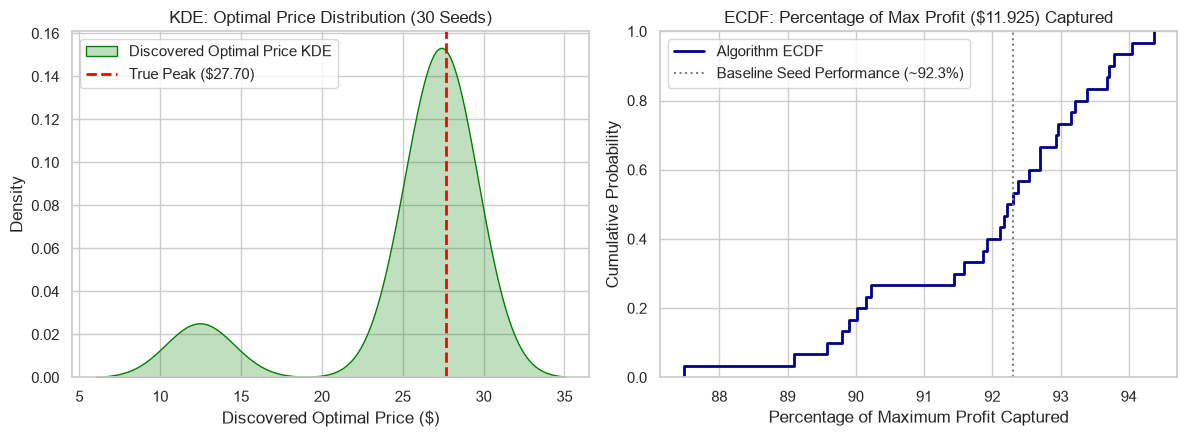

In [53]:
R_sims = 30
sample_optimal_prices = []
sample_pct_profits = []

for s in range(2000, 2000 + R_sims):
    true_sample, opt_p_sample, _, _ = find_optimal_price_algorithm(seed=s)
    sample_optimal_prices.append(opt_p_sample)

    avg_rev = (
        true_sample.total_revenue_accumulated / true_sample.total_customers_tested
    )
    sample_pct_profits.append((avg_rev / 11.925) * 100)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.kdeplot(
    sample_optimal_prices,
    ax=axes[0],
    fill=True,
    color="green",
    bw_adjust=0.8,
    label="Discovered Optimal Price KDE",
)
axes[0].axvline(
    27.70, color="red", linestyle="--", linewidth=2, label="True Peak ($27.70)"
)
axes[0].set_title(f"KDE: Optimal Price Distribution ({R_sims} Seeds)")
axes[0].set_xlabel("Discovered Optimal Price ($)")
axes[0].set_ylabel("Density")
axes[0].legend()

sns.ecdfplot(
    sample_pct_profits,
    ax=axes[1],
    color="darkblue",
    linewidth=2,
    label="Algorithm ECDF",
)
axes[1].axvline(
    92.30,
    color="gray",
    linestyle=":",
    linewidth=1.5,
    label="Baseline Seed Performance (~92.3%)",
)
axes[1].set_title("ECDF: Percentage of Max Profit ($11.925) Captured")
axes[1].set_xlabel("Percentage of Maximum Profit Captured")
axes[1].set_ylabel("Cumulative Probability")
axes[1].legend()

plt.show()


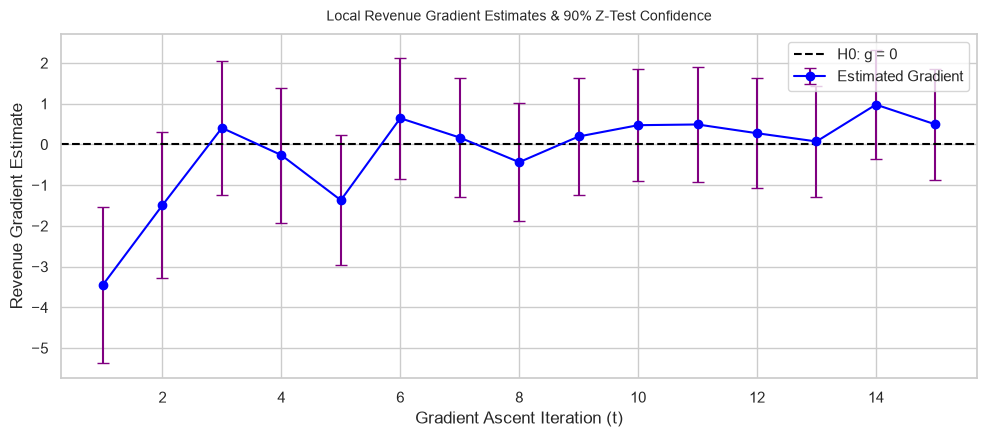

In [54]:
fig, ax = plt.subplots(figsize=(10, 4.5))
iters = path_df["iteration"]
grads = path_df["gradient"]
ci_lows = path_df["ci_low"]
ci_highs = path_df["ci_high"]
#local gradient estimates with 90% CI
ax.errorbar( iters, grads, yerr=[grads - ci_lows, ci_highs - grads], fmt="o-", color="blue", ecolor="purple", capsize=4, linewidth=1.5, label=r"Estimated Gradient", )
ax.axhline(0, color="black", linestyle="--", linewidth=1.5, label="H0: g = 0")
ax.set_title( "Local Revenue Gradient Estimates & 90% Z-Test Confidence", fontsize= 10, pad=10, ) 
ax.set_xlabel("Gradient Ascent Iteration (t)") 
ax.set_ylabel("Revenue Gradient Estimate") 
ax.legend(loc="upper right") 
plt.show()

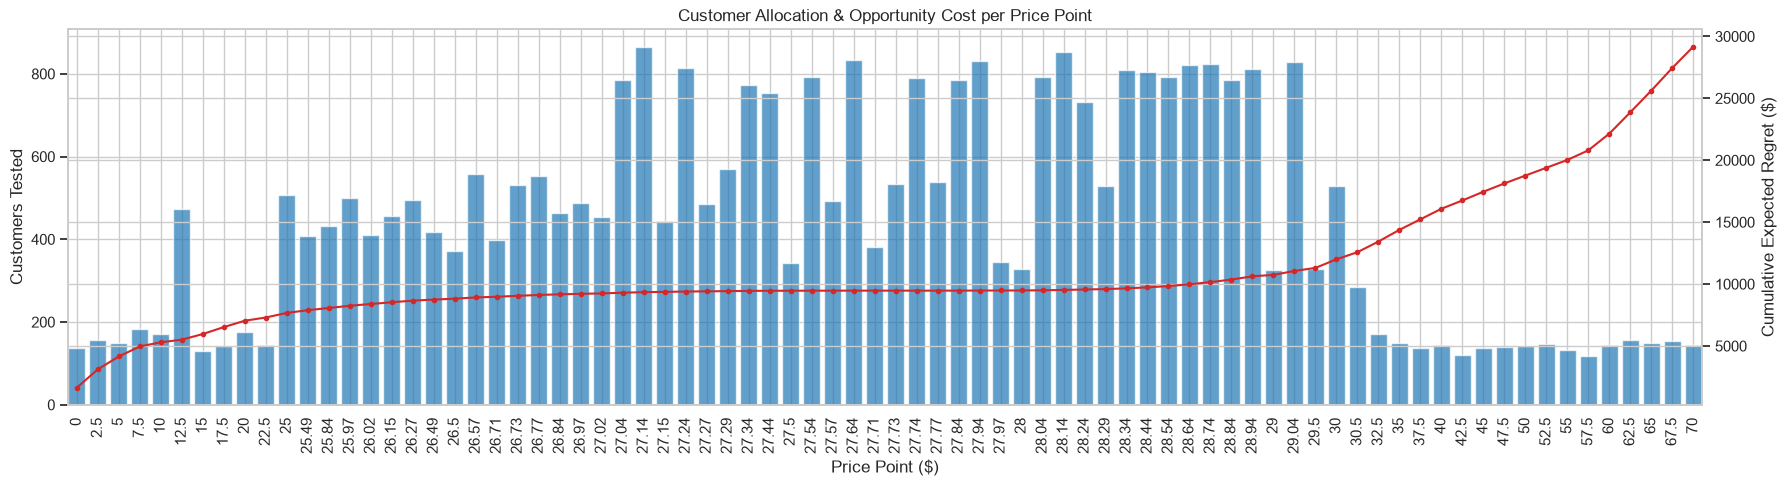

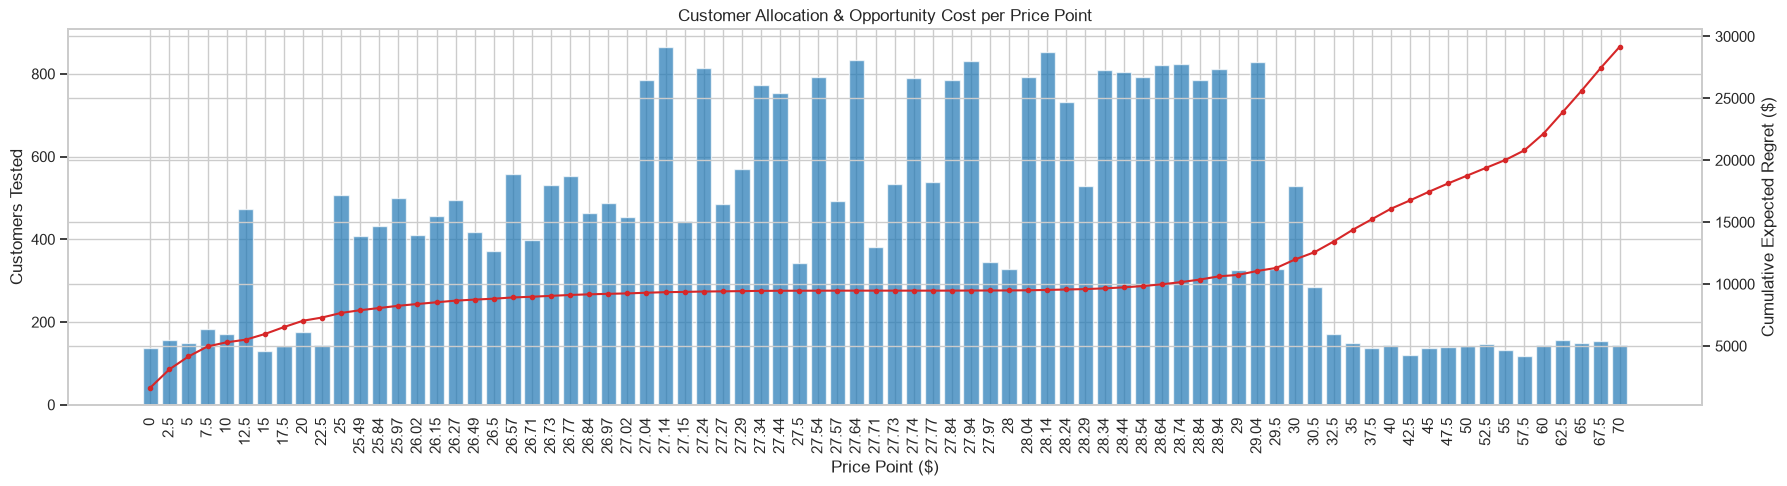

In [60]:
plot_df = pd.DataFrame(cache_data).sort_values("price").reset_index(drop=True)

x = np.arange(len(plot_df))

fig, ax1 = plt.subplots(figsize=(18, 5))
ax1.bar(x, plot_df["customers"], color="tab:blue", alpha=0.7)
ax1.set_ylabel("Customers Tested")

ax2 = ax1.twinx()
ax2.plot(
    x,
    plot_df["total_regret"].cumsum(),
    color="tab:red",
    marker="o",
    markersize=3,
)
ax2.set_ylabel("Cumulative Expected Regret ($)")

ax1.set_xlim(-0.4, len(plot_df) - 0.6)
ax1.set_xticks(x)
ax1.set_xticklabels(plot_df["price"].map(lambda value: f"{value:g}"), rotation=90)
ax1.set_xlabel("Price Point ($)")
ax1.set_title("Customer Allocation & Opportunity Cost per Price Point")

plt.tight_layout()
plt.show()
x = np.arange(len(plot_df))

fig, ax1 = plt.subplots(figsize=(18, 5))
ax1.bar(x, plot_df["customers"], color="tab:blue", alpha=0.7)
ax1.set_ylabel("Customers Tested")

ax2 = ax1.twinx()
ax2.plot(
    x,
    plot_df["total_regret"].cumsum(),
    color="tab:red",
    marker="o",
    markersize=3,
)
ax2.set_ylabel("Cumulative Expected Regret ($)")

ax1.set_xticks(x)
ax1.set_xticklabels(plot_df["price"].map(lambda value: f"{value:g}"), rotation=90)
ax1.set_xlabel("Price Point ($)")
ax1.set_title("Customer Allocation & Opportunity Cost per Price Point")

plt.tight_layout()
plt.show()
